# CICIoT2023 — Leak-free, open-world IoT intrusion detection (CPU-only)

**One notebook, top to bottom.** Your CSV folder has **one sub-folder per label** (34 folders: `Benign_Final` + 33 attacks) plus `README_CSV.pdf`. The notebook therefore starts with a full **data inventory** (Section 0), then audits/de-duplicates (Section 1), then runs the experiments.

**Everything this notebook writes goes into ONE folder:** `<PROJECT>\CICIoT2023_OpenSet_RUN\`
```
CICIoT2023_OpenSet_RUN\
  README_RUN.txt
  _shared\00_inventory\   folder/file inventory, header check, feature profile
  _shared\01_audit\       duplicates, conflicts, file manifest, raw sample, meta.json
  _shared\02_clean_parquet\   de-duplicated data (reused by every profile)
  <PROFILE>\tables\  figures\  artifacts\  logs\run_log.txt  run_config.json
```
**How to run:** install packages → set `PROFILE` → Run All. Start with `"smoke"` (1 file per folder, first 20,000 rows each; numbers are *not* meaningful), then `"fast"`, then `"full"`.

| Section | Output |
|---|---|
| 0 Inventory | every folder/file, headers, label column?, row counts (optional), ordering check, feature profile |
| 1 Audit | duplicates, label conflicts, per-file manifest, clean Parquet |
| 2 Working set | capped, near-duplicate-grouped data |
| 3 RQ1 | how much results drop under leak-free protocols |
| 4 RQ2/RQ3 | unseen-family detection, baselines vs proposed method |
| 5 Analysis | tables, Friedman/Wilcoxon, paired bootstrap, ablation, figures |
| 6 Optional | leave-one-attack-out + novelty-distance analysis |

In [1]:
# Run once (remove the leading # to install), then restart the kernel if needed.
# %pip install -q pandas numpy scipy scikit-learn matplotlib pyarrow lightgbm

In [2]:
import os
from pathlib import Path

PROJECT = Path(os.environ.get("CICIOT_PROJECT", r"C:\Users\kiani\DTESI2027_IoT_Security"))
CSV_DIR = PROJECT / "data" / "raw" / "CSV"          # contains one sub-folder per label (+ README_CSV.pdf)

# ---- ONE root folder for everything this notebook writes -------------------------------------
RUN_ROOT   = PROJECT / "CICIoT2023_OpenSet_RUN"
SHARED_DIR = RUN_ROOT / "_shared"                   # reused by all profiles
INV_DIR    = SHARED_DIR / "00_inventory"
OUT_DIR    = SHARED_DIR / "01_audit"
CLEAN_DIR  = SHARED_DIR / "02_clean_parquet"

PROFILE = os.environ.get("CICIOT_PROFILE", "smoke")  # "smoke" -> "fast" -> "full"
RES_DIR = RUN_ROOT / PROFILE
TAB_DIR, FIG_DIR, ART_DIR, LOG_DIR = (RES_DIR / n for n in ("tables", "figures", "artifacts", "logs"))
for d in (INV_DIR, OUT_DIR, CLEAN_DIR, TAB_DIR, FIG_DIR, ART_DIR, LOG_DIR): d.mkdir(parents=True, exist_ok=True)

SEED = 42
CONFLICTS = "drop"     # same feature vector under >1 label: "drop" (strict) or "keep" (one copy per label)
COUNT_ROWS = False     # Section 0: also count rows of every file (reads all bytes once; slower)
FORCE_AUDIT = False    # True = redo Section 1 even if outputs exist
RUN_LOAO = False       # Section 6: leave-one-ATTACK-out (33 folds, slow)
ALPHA = 0.05           # target false-alarm rate on known traffic (conformal threshold)

PROFILES = {   # files_per_folder / rows_per_file: 0 = use everything
    "smoke": dict(files_per_folder=1, rows_per_file=20000, raw_frac=0.30, cap_per_label=300,   benign_cap=1500,
                  n_trees=20,  knn_ref=2000,  knn_k=5, iforest_n=2000,  eval_cap=3000,
                  inner_cap=1500, n_boot=20,  loao_trees=15,  loao_max_labels=4),
    "fast":  dict(files_per_folder=0, rows_per_file=0, raw_frac=0.02, cap_per_label=3000,  benign_cap=30000,
                  n_trees=100, knn_ref=15000, knn_k=5, iforest_n=20000, eval_cap=20000,
                  inner_cap=8000, n_boot=100, loao_trees=60,  loao_max_labels=0),
    "full":  dict(files_per_folder=0, rows_per_file=0, raw_frac=0.02, cap_per_label=12000, benign_cap=100000,
                  n_trees=250, knn_ref=40000, knn_k=5, iforest_n=50000, eval_cap=50000,
                  inner_cap=20000, n_boot=200, loao_trees=120, loao_max_labels=0),
}
cfg = PROFILES[PROFILE]
print("CSV_DIR :", CSV_DIR, "| exists:", CSV_DIR.exists())
print("RUN_ROOT:", RUN_ROOT)
print("PROFILE :", PROFILE, cfg)

CSV_DIR : C:\Users\kiani\DTESI2027_IoT_Security\data\raw\CSV | exists: True
RUN_ROOT: C:\Users\kiani\DTESI2027_IoT_Security\CICIoT2023_OpenSet_RUN
PROFILE : smoke {'files_per_folder': 1, 'rows_per_file': 20000, 'raw_frac': 0.3, 'cap_per_label': 300, 'benign_cap': 1500, 'n_trees': 20, 'knn_ref': 2000, 'knn_k': 5, 'iforest_n': 2000, 'eval_cap': 3000, 'inner_cap': 1500, 'n_boot': 20, 'loao_trees': 15, 'loao_max_labels': 4}


In [3]:
%matplotlib inline
import sys, json, glob, time, warnings, pickle, re, csv, hashlib, platform, datetime
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy import stats
import sklearn
from sklearn.ensemble import HistGradientBoostingClassifier, IsolationForest
from sklearn.neighbors import NearestNeighbors
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score,
                             accuracy_score, matthews_corrcoef)

warnings.filterwarnings("ignore")
try:
    import pyarrow  # noqa: F401
except ImportError:
    raise ImportError("pyarrow is required:  pip install pyarrow")
try:
    import lightgbm as lgb
    HAS_LGB = True
except ImportError:
    HAS_LGB = False
    print("lightgbm not installed -> using sklearn HistGradientBoosting (slower). Recommended: pip install lightgbm")


# ---- mirror everything printed to <RUN_ROOT>/<PROFILE>/logs/run_log.txt
class Tee:
    def __init__(self, a, f): self.a, self.f = a, f
    def write(self, s): self.a.write(s); self.f.write(s); return len(s)
    def flush(self): self.a.flush(); self.f.flush()
    def __getattr__(self, n): return getattr(self.a, n)
if not isinstance(sys.stdout, Tee):
    sys.stdout = Tee(sys.stdout, open(LOG_DIR / "run_log.txt", "a", encoding="utf-8", buffering=1))

run_info = dict(started=datetime.datetime.now().isoformat(timespec="seconds"), profile=PROFILE, cfg=cfg, seed=SEED,
                alpha=ALPHA, conflicts=CONFLICTS, csv_dir=str(CSV_DIR), python=platform.python_version(),
                pandas=pd.__version__, numpy=np.__version__, sklearn=sklearn.__version__,
                lightgbm=(lgb.__version__ if HAS_LGB else None), cpu_cores=os.cpu_count())
json.dump(run_info, open(RES_DIR / "run_config.json", "w"), indent=2)
(RUN_ROOT / "README_RUN.txt").write_text(
    "CICIoT2023_OpenSet_Pipeline.ipynb writes ONLY inside this folder.\n"
    "_shared/00_inventory     data inventory (folders, files, headers, feature profile)\n"
    "_shared/01_audit         duplicates / conflicts / file manifest / raw sample / meta.json\n"
    "_shared/02_clean_parquet de-duplicated data reused by every profile\n"
    "<PROFILE>/tables         result tables (CSV)\n<PROFILE>/figures        figures (PNG, 300 dpi)\n"
    "<PROFILE>/artifacts      pickled intermediate results\n<PROFILE>/logs           run_log.txt (full console log)\n"
    "<PROFILE>/run_config.json settings + package versions of the last run\n", encoding="utf-8")
print(f"cpu cores={os.cpu_count()} | lightgbm={HAS_LGB} | log: {LOG_DIR / 'run_log.txt'}")
if PROFILE == "smoke":
    print("*** SMOKE TEST: numbers are NOT meaningful. Switch PROFILE to 'fast' or 'full' for results. ***")


# ---------------------------------------------------------------- helpers
def norm_key(s):
    return re.sub(r"[^a-z0-9]", "", str(s).lower())


def label_to_family(lbl):
    # Fine-grained CICIoT2023 label -> one of 7 attack families (+Benign). Check 'Other' in the audit output.
    s = str(lbl).strip(); low = s.lower(); flat = low.replace("_", "").replace(" ", "")
    if low.startswith("benign"): return "Benign"
    if low.startswith("ddos"):   return "DDoS"
    if low.startswith("dos"):    return "DoS"
    if low.startswith("mirai"):  return "Mirai"
    if low.startswith("recon") or "scan" in low: return "Recon"
    if "brute" in low:           return "BruteForce"
    if "spoof" in low or low.startswith("mitm"): return "Spoofing"
    if any(w in flat for w in ["sqlinjection", "commandinjection", "backdoor", "upload", "xss", "browserhijack"]):
        return "Web"
    return "Other"


def group_partition(groups, fractions, seed):
    # Assign every GROUP (not row) to one part -> no group appears in two parts.
    codes, uniq = pd.factorize(np.asarray(groups))
    u = np.random.default_rng(seed).random(len(uniq))[codes]
    return np.searchsorted(np.cumsum(fractions)[:-1], u, side="right")


def make_model(n_trees, seed):
    if HAS_LGB:
        return lgb.LGBMClassifier(n_estimators=n_trees, learning_rate=0.1, num_leaves=31, subsample=0.8,
                                  subsample_freq=1, colsample_bytree=0.8, class_weight="balanced",
                                  n_jobs=-1, random_state=seed, verbose=-1)
    return HistGradientBoostingClassifier(max_iter=n_trees, learning_rate=0.1, max_leaf_nodes=31,
                                          class_weight="balanced", random_state=seed)


def auc(neg, pos):
    y = np.r_[np.zeros(len(neg)), np.ones(len(pos))]
    return roc_auc_score(y, np.r_[neg, pos])


def eval_scores(neg, pos):
    # neg = scores of known/benign test rows, pos = scores of unseen-attack rows (higher = more 'unknown')
    if len(neg) == 0 or len(pos) == 0:
        return dict(auroc=np.nan, aupr=np.nan, tpr_fpr1=np.nan, tpr_fpr5=np.nan)
    y = np.r_[np.zeros(len(neg)), np.ones(len(pos))]; s = np.r_[neg, pos]
    f = lambda a: float((pos > np.quantile(neg, 1 - a)).mean())
    return dict(auroc=roc_auc_score(y, s), aupr=average_precision_score(y, s),
                tpr_fpr1=f(0.01), tpr_fpr5=f(0.05))


def conformal_threshold(cal_neg, alpha):
    # split-conformal: FPR <= alpha on exchangeable known data
    n = len(cal_neg); k = int(np.ceil((n + 1) * (1 - alpha)))
    s = np.sort(cal_neg)
    return s[k - 1] if k <= n else s[-1] + 1e-9

cpu cores=22 | lightgbm=True | log: C:\Users\kiani\DTESI2027_IoT_Security\CICIoT2023_OpenSet_RUN\smoke\logs\run_log.txt
*** SMOKE TEST: numbers are NOT meaningful. Switch PROFILE to 'fast' or 'full' for results. ***


## 0 · Data inventory (read this output carefully before trusting anything else)

Walks `CSV_DIR` recursively and reports, **per folder and per file**: number of files, size, header (column names) and whether all files share the same header, whether a `label` column exists (otherwise the **folder name becomes the label**), empty files, non-CSV files (e.g. `README_CSV.pdf`), and optionally row counts. It also checks that the 34 expected label folders are present, whether rows look **time-ordered** inside a file (ratio ≪ 1) or shuffled (≈ 1) — this decides whether a temporal split is meaningful — and profiles each feature (constant columns, ranges, NaNs).

In [4]:
OFFICIAL_LABELS = [
    "BenignTraffic", "Backdoor_Malware", "BrowserHijacking", "CommandInjection", "DDoS-ACK_Fragmentation",
    "DDoS-HTTP_Flood", "DDoS-ICMP_Flood", "DDoS-ICMP_Fragmentation", "DDoS-PSHACK_Flood", "DDoS-RSTFINFlood",
    "DDoS-SlowLoris", "DDoS-SYN_Flood", "DDoS-SynonymousIP_Flood", "DDoS-TCP_Flood", "DDoS-UDP_Flood",
    "DDoS-UDP_Fragmentation", "DictionaryBruteForce", "DNS_Spoofing", "DoS-HTTP_Flood", "DoS-SYN_Flood",
    "DoS-TCP_Flood", "DoS-UDP_Flood", "Mirai-greeth_flood", "Mirai-greip_flood", "Mirai-udpplain",
    "MITM-ArpSpoofing", "Recon-HostDiscovery", "Recon-OSScan", "Recon-PingSweep", "Recon-PortScan",
    "SqlInjection", "Uploading_Attack", "VulnerabilityScan", "XSS"]
EXPECTED = {norm_key(l): l for l in OFFICIAL_LABELS}
EXPECTED["benignfinal"] = "BenignTraffic"          # your folder is called Benign_Final


def read_header(path):
    with open(path, "r", encoding="utf-8-sig", errors="replace") as fh:
        line = fh.readline()
    return [c.strip() for c in next(csv.reader([line.rstrip("\r\n")]))] if line.strip() else []


def count_rows_fast(path):
    n, last = 0, b"\n"
    with open(path, "rb") as fh:
        while True:
            b = fh.read(1 << 24)
            if not b: break
            n += b.count(b"\n"); last = b[-1:]
    if last != b"\n": n += 1
    return max(n - 1, 0)                              # minus header


def order_ratio(num):
    # ~1.0 -> rows shuffled; << 1 -> neighbouring rows are similar (time/capture order preserved)
    num = num.loc[:, num.std() > 0]
    if len(num) < 200 or num.shape[1] == 0: return np.nan
    Z = ((num - num.mean()) / num.std()).fillna(0).to_numpy()
    adj = np.abs(Z[1:] - Z[:-1]).mean(0)
    rnd = np.abs(Z - Z[np.random.default_rng(0).permutation(len(Z))]).mean(0)
    return float(np.median(adj / np.maximum(rnd, 1e-9)))


def run_inventory(csv_dir, count_rows):
    csv_dir = Path(csv_dir)
    if not csv_dir.exists(): raise FileNotFoundError(f"CSV_DIR not found: {csv_dir}")
    recs = []
    for p in sorted(csv_dir.rglob("*")):
        if p.is_file():
            rel = p.relative_to(csv_dir)
            recs.append(dict(path=str(p), rel=str(rel), top_folder=rel.parts[0] if len(rel.parts) > 1 else "",
                             ext=p.suffix.lower(), size=p.stat().st_size))
    allf = pd.DataFrame(recs)
    if allf.empty: raise FileNotFoundError(f"No files under {csv_dir}")
    other = allf[allf["ext"] != ".csv"].copy()
    csvf = allf[allf["ext"] == ".csv"].copy().reset_index(drop=True)
    if csvf.empty: raise FileNotFoundError(f"No .csv files under {csv_dir}")

    heads = [read_header(p) for p in csvf["path"]]
    csvf["n_cols"] = [len(h) for h in heads]
    csvf["has_label_col"] = [any(c.lower() == "label" for c in h) for h in heads]
    csvf["header_sig"] = [hashlib.md5("|".join(h).encode()).hexdigest()[:8] for h in heads]
    if count_rows: csvf["rows"] = [count_rows_fast(p) for p in csvf["path"]]
    csvf["empty"] = (csvf["size"] == 0) | (csvf["n_cols"] == 0)
    if count_rows: csvf["empty"] |= (csvf["rows"] == 0)

    var = csvf.groupby("header_sig").agg(n_files=("path", "size"), n_cols=("n_cols", "first")).sort_values("n_files", ascending=False)
    ref_cols = heads[int(csvf.index[csvf["header_sig"] == var.index[0]][0])]
    diffs = {}
    for sig in var.index[1:]:
        h = heads[int(csvf.index[csvf["header_sig"] == sig][0])]
        diffs[sig] = dict(n_files=int(var.loc[sig, "n_files"]), missing_vs_majority=[c for c in ref_cols if c not in h],
                          extra_vs_majority=[c for c in h if c not in ref_cols])

    prof, frows = [], []
    for top, g in csvf.groupby("top_folder", sort=True):
        ok = g[~g["empty"]]
        ratio, nonnum = np.nan, np.nan
        if len(ok):
            try:
                d = pd.read_csv(ok.iloc[0]["path"], nrows=20000, low_memory=False); d.columns = [str(c).strip() for c in d.columns]
                num = d[[c for c in d.columns if c.lower() != "label"]].apply(pd.to_numeric, errors="coerce")
                nonnum = int(num.isna().all().sum()); ratio = order_ratio(num)
                prof.append(num.sample(min(2000, len(num)), random_state=0))
            except Exception as e:
                print(f"  [warn] could not sample {ok.iloc[0]['rel']}: {e}")
        canon = EXPECTED.get(norm_key(top), top) if top else "(files directly in CSV_DIR)"
        frows.append(dict(folder=top, label=canon, family=label_to_family(canon), n_files=len(g),
                          size_MB=round(g["size"].sum() / 1e6, 1),
                          rows=(int(g["rows"].sum()) if count_rows else np.nan), n_header_variants=g["header_sig"].nunique(),
                          files_with_label_col=int(g["has_label_col"].sum()), empty_files=int(g["empty"].sum()),
                          order_ratio=round(ratio, 3) if ratio == ratio else np.nan, fully_nonnumeric_cols=nonnum,
                          expected_label=(norm_key(top) in EXPECTED)))
    folders = pd.DataFrame(frows)

    fp = None
    if prof:
        P = pd.concat(prof, ignore_index=True)
        fp = pd.DataFrame({"n_unique_in_sample": P.nunique(), "std": P.std().round(6), "min": P.min(), "max": P.max(),
                           "pct_nan": (100 * P.isna().mean()).round(3), "pct_zero": (100 * (P == 0).mean()).round(2)})
        fp["constant"] = fp["std"].fillna(0) == 0
        fp.index.name = "feature"

    found = {norm_key(t) for t in folders["folder"] if t}
    exp = set(EXPECTED) - {"benigntraffic"}                       # benign is expected as 'benignfinal' here
    exp_missing = sorted(EXPECTED[k] for k in exp - found - ({"benignfinal"} if "benigntraffic" in found else set()))
    unexpected = sorted(t for t in folders["folder"] if t and norm_key(t) not in EXPECTED)

    csvf.drop(columns=["ext"]).to_csv(INV_DIR / "files_inventory.csv", index=False)
    folders.to_csv(INV_DIR / "folder_summary.csv", index=False)
    other.to_csv(INV_DIR / "non_csv_files.csv", index=False)
    if fp is not None: fp.to_csv(INV_DIR / "feature_profile.csv")
    json.dump(dict(header_variants=var.reset_index().to_dict("records"), differences_vs_majority=diffs,
                   majority_header=ref_cols), open(INV_DIR / "header_check.json", "w"), indent=1)
    return dict(csvf=csvf, folders=folders, other=other, variants=var, diffs=diffs, ref_cols=ref_cols,
                fp=fp, exp_missing=exp_missing, unexpected=unexpected, count_rows=count_rows)


INV = run_inventory(CSV_DIR, COUNT_ROWS)
csvf, folders = INV["csvf"], INV["folders"]
n_attack_folders = int(sum(1 for f in folders["family"] if f not in ("Benign",)))
print(f"CSV files: {len(csvf):,} in {folders['folder'].nunique()} folder(s) | total {csvf['size'].sum()/1e9:.2f} GB")
print(f"Non-CSV files: {INV['other']['rel'].tolist()}")
print(f"Attack folders: {n_attack_folders} (the dataset page says 33 attacks) | benign folders: {int((folders['family']=='Benign').sum())}")
print("Expected label folders MISSING:", INV["exp_missing"] or "none")
print("Unexpected folder names       :", INV["unexpected"] or "none")
print(f"Header variants across all files: {len(INV['variants'])}  ({int(INV['variants'].iloc[0]['n_cols'])} columns in the majority header)")
for sig, d in INV["diffs"].items(): print("   variant", sig, d)
lab_any = int(csvf["has_label_col"].sum())
print(f"Files with a 'label' column: {lab_any}/{len(csvf)} ->",
      "labels will be read from the column (and cross-checked with the folder name)" if lab_any else
      "NO label column: the FOLDER NAME is used as the label")
print(f"Empty/unreadable files: {int(csvf['empty'].sum())}")
display(folders)
if INV["fp"] is not None:
    const = INV["fp"].index[INV["fp"]["constant"]].tolist()
    print("Constant features in the sample:", const or "none")
    display(INV["fp"])
med_ratio = float(folders["order_ratio"].median())
print(f"Median row-order ratio = {med_ratio:.2f}  (~1 => rows are shuffled inside files; << 1 => capture order preserved)")

CSV files: 309 in 34 folder(s) | total 8.94 GB
Non-CSV files: ['README_CSV.pdf']
Attack folders: 33 (the dataset page says 33 attacks) | benign folders: 1
Expected label folders MISSING: none
Unexpected folder names       : none
Header variants across all files: 1  (39 columns in the majority header)
Files with a 'label' column: 0/309 -> NO label column: the FOLDER NAME is used as the label
Empty/unreadable files: 0


,folder,label,family,n_files,size_MB,rows,n_header_variants,files_with_label_col,empty_files,order_ratio,fully_nonnumeric_cols,expected_label
0,Backdoor_Malware,Backdoor_Malware,Web,1,0.7,NaN,1,0,0,0.762,0,True
1,Benign_Final,BenignTraffic,Benign,4,227.4,NaN,1,0,0,0.724,0,True
2,BrowserHijacking,BrowserHijacking,Web,1,1.2,NaN,1,0,0,0.685,0,True
3,CommandInjection,CommandInjection,Web,1,1.1,NaN,1,0,0,0.779,0,True
4,DDoS-ACK_Fragmentation,DDoS-ACK_Fragmentation,DDoS,13,62.8,NaN,1,0,0,0.750,0,True
5,DDoS-HTTP_Flood,DDoS-HTTP_Flood,DDoS,1,6.4,NaN,1,0,0,0.617,0,True
6,DDoS-ICMP_Flood,DDoS-ICMP_Flood,DDoS,27,1326.3,NaN,1,0,0,0.967,0,True
7,DDoS-ICMP_Fragmentation,DDoS-ICMP_Fragmentation,DDoS,20,99.7,NaN,1,0,0,0.771,0,True
8,DDoS-PSHACK_FLOOD,DDoS-PSHACK_Flood,DDoS,16,769.6,NaN,1,0,0,0.878,0,True
9,DDoS-RSTFINFLOOD,DDoS-RSTFINFlood,DDoS,16,767.0,NaN,1,0,0,0.945,0,True


Constant features in the sample: ['Rate']


,n_unique_in_sample,std,min,max,pct_nan,pct_zero,constant
feature,,,,,,,
Header_Length,1074,10.601535,0.000000e+00,6.000000e+01,0.000,6.66,False
Protocol Type,5,10.324532,0.000000e+00,4.700000e+01,0.000,0.80,False
Time_To_Live,4063,33.609924,0.000000e+00,2.550000e+02,0.000,0.08,False
Rate,53918,NaN,9.746343e-03,inf,0.000,0.00,True
fin_flag_number,86,0.173568,0.000000e+00,1.000000e+00,0.000,82.51,False
syn_flag_number,125,0.295833,0.000000e+00,1.000000e+00,0.000,65.64,False
rst_flag_number,120,0.213892,0.000000e+00,1.000000e+00,0.000,83.41,False
psh_flag_number,123,0.220702,0.000000e+00,1.000000e+00,0.000,53.68,False
ack_flag_number,145,0.397161,0.000000e+00,1.000000e+00,0.000,34.39,False


Median row-order ratio = 0.76  (~1 => rows are shuffled inside files; << 1 => capture order preserved)


## 1 · Audit and de-duplication

Reads every (selected) file in chunks, hashes each feature vector, and finds **exact duplicates** and **label conflicts** (identical vector under different labels — expected e.g. between `DDoS-SYN_Flood` and `DoS-SYN_Flood`). If a file has no `label` column, the folder name is the label; if it has one, it is cross-checked against the folder (mismatches are counted per file in `file_manifest.csv`). Output: de-duplicated Parquet in `_shared\02_clean_parquet`.

In [5]:
META_JSON  = OUT_DIR / "meta.json"
RAW_SAMPLE = OUT_DIR / "raw_sample.parquet"
CHUNK = 500_000


def build_file_list(csvf, cfg):
    f = csvf[~csvf["empty"]].sort_values(["top_folder", "rel"])
    if cfg["files_per_folder"]: f = f.groupby("top_folder", sort=True).head(cfg["files_per_folder"])
    return f.reset_index(drop=True)


def run_audit(csvf, out_dir, cfg, conflicts):
    files = build_file_list(csvf, cfg)
    if files.empty: raise FileNotFoundError("No non-empty CSV files to audit.")
    canon = {norm_key(t): EXPECTED.get(norm_key(t), t) for t in files["top_folder"].unique() if t}
    canon["benigntraffic"] = "BenignTraffic"
    to_canon = lambda s: canon.get(norm_key(s), EXPECTED.get(norm_key(s), str(s).strip()))
    st = {"feat": None}
    rng = np.random.default_rng(SEED)

    def iter_chunks(rec):
        # yields (features float32 DataFrame, canonical labels ndarray, label-mismatch count) per chunk
        folder_label = to_canon(rec.top_folder) if rec.top_folder else None
        try:
            reader = pd.read_csv(rec.path, chunksize=CHUNK, low_memory=False, nrows=(cfg["rows_per_file"] or None))
            for chunk in reader:
                chunk.columns = [str(c).strip() for c in chunk.columns]
                lc = next((c for c in chunk.columns if c.lower() == "label"), None)
                if st["feat"] is None: st["feat"] = [c for c in chunk.columns if c != lc]
                miss = [c for c in st["feat"] if c not in chunk.columns]
                if miss: raise KeyError(f"{rec.rel}: missing feature columns {miss[:5]}...")
                x = chunk[st["feat"]].apply(pd.to_numeric, errors="coerce").astype("float32").reset_index(drop=True)
                if lc is not None:
                    codes, uniq = pd.factorize(chunk[lc].astype(str).str.strip())
                    labs = np.array([to_canon(u) for u in uniq], dtype=object)[codes]
                    mism = int((labs != folder_label).sum()) if folder_label else 0
                else:
                    if folder_label is None: raise ValueError(f"{rec.rel}: no label column and no folder to take a label from")
                    labs = np.full(len(x), folder_label, dtype=object); mism = 0
                yield x, labs, mism, lc is not None
        except pd.errors.EmptyDataError:
            print(f"  [skip] empty file: {rec.rel}")

    label_index, H, Y, Fl, raw_parts, manifest = {}, [], [], [], [], []
    t0 = time.time()
    # ---------- pass 1 ----------
    for fid, rec in enumerate(files.itertuples()):
        n_rows = nan_rows = mism_rows = 0; from_col = False
        for x, labs, mism, from_col in iter_chunks(rec):
            arr = x.to_numpy(); nan_rows += int((~np.isfinite(arr)).any(1).sum()); mism_rows += mism
            h = pd.util.hash_pandas_object(x, index=False).to_numpy(dtype="uint64")
            codes, uniq = pd.factorize(labs)
            gmap = np.array([label_index.setdefault(u, len(label_index)) for u in uniq], dtype="int16")
            H.append(h); Y.append(gmap[codes]); Fl.append(np.full(len(x), fid, dtype="int16")); n_rows += len(x)
            if cfg["raw_frac"] > 0:
                m = rng.random(len(x)) < cfg["raw_frac"]
                if m.any():
                    s = x[m].reset_index(drop=True); s["label"] = labs[m]; s["file_id"] = np.int16(fid); raw_parts.append(s)
        manifest.append(dict(file_id=fid, rel=rec.rel, folder=rec.top_folder, label_source="column" if from_col else "folder",
                             rows_read=n_rows, nonfinite_rows=nan_rows, label_mismatch_vs_folder=mism_rows, bytes=rec.size))
        if (fid + 1) % 10 == 0 or fid + 1 == len(files):
            print(f"  pass1 [{fid+1}/{len(files)}] {rec.rel}  ({time.time()-t0:.0f}s)")
    if not H: raise RuntimeError("No rows were read.")

    h_all, y_all, f_all = np.concatenate(H), np.concatenate(Y), np.concatenate(Fl); del H, Y, Fl
    classes = np.array(sorted(label_index, key=label_index.get))
    fam_map = {c: label_to_family(c) for c in classes}

    # ---------- duplicates and label conflicts ----------
    df = pd.DataFrame({"h": h_all, "y": y_all, "f": f_all})
    dup_same = df.duplicated(subset=["h", "y"], keep="first").to_numpy()
    uq = df.loc[~dup_same, ["h", "y"]]
    conflict_hash = uq.loc[uq["h"].duplicated(keep=False), "h"].unique()
    in_conflict = df["h"].isin(conflict_hash).to_numpy()
    hf = df[["h", "f"]].drop_duplicates()["h"].value_counts()
    keep = ~dup_same
    if conflicts == "drop": keep &= ~in_conflict
    del df, uq

    n_cls = len(classes)
    by_label = pd.DataFrame({
        "label": classes, "family": [fam_map[c] for c in classes],
        "rows_raw": np.bincount(y_all, minlength=n_cls), "rows_dup": np.bincount(y_all[dup_same], minlength=n_cls),
        "rows_conflict": np.bincount(y_all[in_conflict], minlength=n_cls), "rows_kept": np.bincount(y_all[keep], minlength=n_cls)})
    by_label["dup_pct"] = (100 * by_label.rows_dup / by_label.rows_raw).round(2)
    by_label.to_csv(out_dir / "label_audit.csv", index=False)

    # conflicting label pairs (which labels share identical feature vectors)
    pairs = pd.DataFrame({"h": h_all[in_conflict], "y": y_all[in_conflict]}).drop_duplicates()
    pc = {}
    for _, g in pairs.groupby("h")["y"]:
        ys = sorted(g.tolist())
        for i in range(len(ys)):
            for j in range(i + 1, len(ys)): pc[(classes[ys[i]], classes[ys[j]])] = pc.get((classes[ys[i]], classes[ys[j]]), 0) + 1
    pd.DataFrame([dict(label_a=a, label_b=b, shared_vectors=n) for (a, b), n in pc.items()],
                 columns=["label_a", "label_b", "shared_vectors"]).sort_values(
        "shared_vectors", ascending=False).to_csv(out_dir / "label_conflict_pairs.csv", index=False)

    if raw_parts:
        raw = pd.concat(raw_parts, ignore_index=True); raw["family"] = raw["label"].map(fam_map)
        raw.to_parquet(RAW_SAMPLE, index=False)

    # ---------- pass 2: write clean (de-duplicated) parquet ----------
    pos = 0; nonfinite = 0
    for fid, rec in enumerate(files.itertuples()):
        parts, row0 = [], 0
        for x, labs, mism, _ in iter_chunks(rec):
            n = len(x); m = keep[pos:pos + n]
            if m.any():
                xm = x[m].reset_index(drop=True); fin = np.isfinite(xm.to_numpy()).all(1)
                xm["label"] = labs[m]; xm["family"] = pd.Series(labs[m]).map(fam_map).to_numpy()
                xm["file_id"] = np.int16(fid); xm["row_in_file"] = (np.arange(n)[m] + row0).astype("int32")
                nonfinite += int((~fin).sum()); parts.append(xm[fin])
            pos += n; row0 += n
        if parts: pd.concat(parts, ignore_index=True).to_parquet(CLEAN_DIR / f"part_{fid:05d}.parquet", index=False)
        if (fid + 1) % 10 == 0 or fid + 1 == len(files): print(f"  pass2 [{fid+1}/{len(files)}] ({time.time()-t0:.0f}s)")

    pd.DataFrame(manifest).to_csv(out_dir / "file_manifest.csv", index=False)
    total = int(len(h_all))
    summary = dict(files_read=len(files), total_rows=total, n_features=len(st["feat"]),
                   rows_nonfinite=int(sum(m_["nonfinite_rows"] for m_ in manifest)),
                   exact_duplicate_rows=int(dup_same.sum()), exact_duplicate_pct=round(100 * float(dup_same.mean()), 3),
                   rows_in_label_conflict=int(in_conflict.sum()), vectors_present_in_multiple_files=int((hf > 1).sum()),
                   rows_kept=int(keep.sum()), nonfinite_rows_dropped_in_pass2=nonfinite,
                   label_mismatch_rows_vs_folder=int(sum(m_["label_mismatch_vs_folder"] for m_ in manifest)),
                   labels_found=int(n_cls), labels_mapped_to_Other=[c for c in classes if fam_map[c] == "Other"],
                   conflicts_policy=conflicts)
    json.dump(summary, open(out_dir / "summary.json", "w"), indent=2)
    json.dump(dict(feat_cols=st["feat"], classes=list(classes), files_per_folder=cfg["files_per_folder"],
                   rows_per_file=cfg["rows_per_file"], raw_frac=cfg["raw_frac"], conflicts=conflicts,
                   csv_dir=str(CSV_DIR)), open(META_JSON, "w"))
    return summary


def audit_done():
    if not (META_JSON.exists() and RAW_SAMPLE.exists() and any(CLEAN_DIR.glob("part_*.parquet"))): return False
    m = json.load(open(META_JSON))
    return (m.get("files_per_folder") == cfg["files_per_folder"] and m.get("rows_per_file") == cfg["rows_per_file"]
            and m.get("raw_frac") == cfg["raw_frac"] and m.get("conflicts") == CONFLICTS and m.get("csv_dir") == str(CSV_DIR))


if FORCE_AUDIT or not audit_done():
    for p in CLEAN_DIR.glob("part_*.parquet"): p.unlink()
    t0 = time.time(); audit_summary = run_audit(csvf, OUT_DIR, cfg, CONFLICTS)
    print(f"audit finished in {time.time()-t0:.0f}s")
else:
    print("Audit outputs already match this configuration -> skipped (FORCE_AUDIT=True to redo).")
    audit_summary = json.load(open(OUT_DIR / "summary.json"))

meta = json.load(open(META_JSON)); FEATS = meta["feat_cols"]
label_audit = pd.read_csv(OUT_DIR / "label_audit.csv")
print(json.dumps(audit_summary, indent=2))
display(label_audit.sort_values("rows_raw", ascending=False).reset_index(drop=True))
pairs_df = pd.read_csv(OUT_DIR / "label_conflict_pairs.csv")
print("Label pairs that share IDENTICAL feature vectors (top 15):"); display(pairs_df.head(15))
display(pd.read_csv(OUT_DIR / "file_manifest.csv").groupby("folder")[["rows_read", "nonfinite_rows", "label_mismatch_vs_folder"]].sum())

  pass1 [10/34] DDoS-RSTFINFLOOD\DDoS-RSTFINFlood.pcap.csv  (2s)
  pass1 [20/34] DoS-SYN_Flood\DoS-SYN_Flood.pcap.csv  (5s)
  pass1 [30/34] Recon-PortScan\Recon-PortScan.pcap.csv  (7s)
  pass1 [34/34] XSS\XSS.pcap.csv  (8s)
  pass2 [10/34] (13s)
  pass2 [20/34] (16s)
  pass2 [30/34] (20s)
  pass2 [34/34] (20s)
audit finished in 20s
{
  "files_read": 34,
  "total_rows": 560155,
  "n_features": 39,
  "rows_nonfinite": 16,
  "exact_duplicate_rows": 35703,
  "exact_duplicate_pct": 6.374,
  "rows_in_label_conflict": 31062,
  "vectors_present_in_multiple_files": 8537,
  "rows_kept": 506761,
  "nonfinite_rows_dropped_in_pass2": 16,
  "label_mismatch_rows_vs_folder": 0,
  "labels_found": 34,
  "labels_mapped_to_Other": [],
  "conflicts_policy": "drop"
}


,label,family,rows_raw,rows_dup,rows_conflict,rows_kept,dup_pct
0,DDoS-UDP_Fragmentation,DDoS,20000,8,0,19992,0.04
1,DNS_Spoofing,Spoofing,20000,143,215,19772,0.72
2,VulnerabilityScan,Recon,20000,17,8,19976,0.08
3,Recon-OSScan,Recon,20000,197,299,19613,0.98
4,Recon-HostDiscovery,Recon,20000,86,150,19839,0.43
5,Mirai-udpplain,Mirai,20000,41,0,19959,0.20
6,Mirai-greip_flood,Mirai,20000,23,0,19977,0.12
7,Mirai-greeth_flood,Mirai,20000,72,0,19928,0.36
8,MITM-ArpSpoofing,Spoofing,20000,1931,703,17957,9.65
9,DoS-UDP_Flood,DoS,20000,2305,3416,15540,11.52


Label pairs that share IDENTICAL feature vectors (top 15):


,label_a,label_b,shared_vectors
0,DDoS-TCP_Flood,DoS-TCP_Flood,2574
1,DDoS-SYN_Flood,DDoS-SynonymousIP_Flood,2320
2,DDoS-UDP_Flood,DoS-UDP_Flood,2155
3,DDoS-SYN_Flood,DoS-SYN_Flood,1179
4,DDoS-SynonymousIP_Flood,DoS-SYN_Flood,999
5,Recon-OSScan,Recon-PortScan,183
6,DNS_Spoofing,MITM-ArpSpoofing,72
7,MITM-ArpSpoofing,Recon-HostDiscovery,54
8,BrowserHijacking,MITM-ArpSpoofing,48
9,DNS_Spoofing,Recon-HostDiscovery,44


,rows_read,nonfinite_rows,label_mismatch_vs_folder
folder,,,
Backdoor_Malware,3218,0,0
Benign_Final,20000,0,0
BrowserHijacking,5859,0,0
CommandInjection,5409,0,0
DDoS-ACK_Fragmentation,20000,1,0
DDoS-HTTP_Flood,20000,0,0
DDoS-ICMP_Flood,20000,1,0
DDoS-ICMP_Fragmentation,20000,2,0
DDoS-PSHACK_FLOOD,20000,0,0


## 2 · Working set and near-duplicate groups

The clean data is sub-sampled (`cap_per_label`, larger cap for benign). Rows are then grouped by a **near-duplicate key** (every feature quantile-binned; rows with the same bins form a group). All later splits assign whole groups to one side, so near-identical rows can never sit in both train and test.

In [6]:
def X_of(df):
    return df[FEATS].to_numpy(dtype=np.float32)


def load_working_set(cap, benign_cap, seed):
    kept = dict(zip(label_audit["label"], label_audit["rows_kept"]))
    p = {l: min(1.0, (benign_cap if str(l).lower().startswith("benign") else cap) / max(k, 1)) for l, k in kept.items()}
    rng = np.random.default_rng(seed); parts = []
    for f in sorted(CLEAN_DIR.glob("part_*.parquet")):
        d = pd.read_parquet(f)
        pr = d["label"].map(p).fillna(0.0).to_numpy(dtype=float)
        parts.append(d[rng.random(len(d)) < pr])
    return pd.concat(parts, ignore_index=True)


def fit_bins(df, n_bins=16):
    X = df[FEATS].to_numpy(dtype=np.float64)
    return [np.unique(np.quantile(X[:, j], np.linspace(0, 1, n_bins + 1)[1:-1])) for j in range(X.shape[1])]


def neardup_key(df, edges):
    X = df[FEATS].to_numpy(dtype=np.float64)
    codes = np.empty(X.shape, dtype=np.int16)
    for j, e in enumerate(edges): codes[:, j] = np.searchsorted(e, X[:, j], side="right")
    return pd.util.hash_pandas_object(pd.DataFrame(codes), index=False).to_numpy(dtype="uint64")


ws = load_working_set(cfg["cap_per_label"], cfg["benign_cap"], SEED)
n_other = int((ws["family"] == "Other").sum())
if n_other: print(f"WARNING: {n_other} rows have family 'Other' (unmapped labels) and are excluded from open-set experiments.")
BINS = fit_bins(ws)
ws["nk"] = neardup_key(ws, BINS)
ws["ng"] = pd.factorize(ws["nk"])[0]

gs = ws["ng"].value_counts()
print(f"working set: {len(ws):,} rows | {ws['label'].nunique()} labels | {ws['family'].nunique()} families")
print(f"near-dup groups: {len(gs):,} | largest group = {100*gs.iloc[0]/len(ws):.1f}% of rows | "
      f"top-10 groups = {100*gs.iloc[:10].sum()/len(ws):.1f}%")
display(ws["family"].value_counts().to_frame("rows").T)

working set: 11,379 rows | 34 labels | 8 families
near-dup groups: 8,558 | largest group = 0.8% of rows | top-10 groups = 6.3%


family,DDoS,Web,Recon,Benign,DoS,Mirai,Spoofing,BruteForce
rows,3590,1829,1509,1493,1141,894,608,315


## 3 · RQ1 — How much do results change under leak-free protocols?

Same model, same per-label caps, six protocols. `exact_overlap_%` / `neardup_overlap_%` = share of **test** rows whose exact vector / near-duplicate group also appears in **train**. Protocols P0/P0b use a random sample of the *raw* CSV rows (duplicates included), the way many published pipelines do. P3 holds out whole CSV files (classes with a single file disappear from training, so expect a low score). P4 trains on the first 70% of every file and tests on the last 30%; it is only meaningful if Section 0 showed a row-order ratio well below 1.

In [7]:
raw = pd.read_parquet(RAW_SAMPLE)
raw = raw[raw["family"] != "Other"].reset_index(drop=True)
raw["nk"] = neardup_key(raw, BINS)


def cap_labels(df, n, benign_n):
    sh = df.sample(frac=1.0, random_state=SEED).reset_index(drop=True)
    lim = np.where(sh["label"].str.lower().str.startswith("benign"), benign_n, n)
    return sh[sh.groupby("label").cumcount().to_numpy() < lim].reset_index(drop=True)


def keep_min(df, k=5):
    vc = df["label"].value_counts()
    return df[df["label"].isin(vc[vc >= k].index)].reset_index(drop=True)


def oversample_before_split(df):          # the classic leak: resample first, split afterwards
    target = int(df["label"].value_counts().median())
    parts = [df]
    for lab, g in df.groupby("label"):
        if len(g) < target: parts.append(g.sample(target - len(g), replace=True, random_state=SEED))
    return pd.concat(parts, ignore_index=True)


def eval_split(name, tr, te):
    m = make_model(cfg["n_trees"], SEED).fit(X_of(tr), tr["label"].to_numpy())
    pr = m.predict(X_of(te)); yt = te["label"].to_numpy()
    h_tr = pd.util.hash_pandas_object(tr[FEATS], index=False).to_numpy()
    h_te = pd.util.hash_pandas_object(te[FEATS], index=False).to_numpy()
    return dict(protocol=name, n_train=len(tr), n_test=len(te),
                exact_overlap_pct=round(100 * np.isin(h_te, h_tr).mean(), 2),
                neardup_overlap_pct=round(100 * np.isin(te["nk"].to_numpy(), tr["nk"].to_numpy()).mean(), 2),
                accuracy=accuracy_score(yt, pr), macro_f1=f1_score(yt, pr, average="macro"),
                mcc=matthews_corrcoef(yt, pr))


def temporal_split(df, frac=0.7):
    # first `frac` of every file (by original row order) -> train, the rest -> test; meaningful only if capture order is preserved
    mx = df.groupby("file_id")["row_in_file"].transform("max").clip(lower=1)
    pos = df["row_in_file"] / mx
    return df[pos <= frac], df[pos > frac]


def strat_split(df, test_size=0.3):
    return train_test_split(df, test_size=test_size, stratify=df["label"], random_state=SEED)


rows = []
raw_c = keep_min(cap_labels(raw, cfg["cap_per_label"], cfg["benign_cap"]))
ws_c  = keep_min(ws)

tr, te = strat_split(raw_c);                                   rows.append(eval_split("P0  raw rows, random split", tr, te))
tr, te = strat_split(oversample_before_split(raw_c));          rows.append(eval_split("P0b raw, oversample THEN split", tr, te))
tr, te = strat_split(ws_c);                                    rows.append(eval_split("P1  de-duplicated, random split", tr, te))
part = group_partition(ws_c["ng"], [0.7, 0.3], SEED)
rows.append(eval_split("P2  de-dup + near-dup GROUP split", ws_c[part == 0], ws_c[part == 1]))
part = group_partition(ws_c["file_id"], [0.7, 0.3], SEED)
rows.append(eval_split("P3  de-dup + CSV-file GROUP split", ws_c[part == 0], ws_c[part == 1]))

tr, te = temporal_split(ws_c)
if len(tr) and len(te):
    rows.append(eval_split("P4  de-dup + TEMPORAL split inside each file", tr, te))

rq1 = pd.DataFrame(rows)
display(rq1.round(4))
rq1.to_csv(TAB_DIR / "rq1_protocols.csv", index=False)

,protocol,n_train,n_test,exact_overlap_pct,neardup_overlap_pct,accuracy,macro_f1,mcc
0,"P0 raw rows, random split",7980,3420,0.29,29.91,0.6336,0.6387,0.6199
1,"P0b raw, oversample THEN split",7980,3420,0.29,29.91,0.6336,0.6387,0.6199
2,"P1 de-duplicated, random split",7965,3414,0.00,27.24,0.6295,0.6314,0.6153
3,P2 de-dup + near-dup GROUP split,8043,3336,0.00,0.00,0.6211,0.6330,0.6056
4,P3 de-dup + CSV-file GROUP split,7210,4169,0.00,1.37,0.0000,0.0000,0.0000
5,P4 de-dup + TEMPORAL split inside each file,7989,3390,0.00,26.14,0.6109,0.6237,0.5951


## 4 · RQ2 / RQ3 — Detecting unseen attack families, with a calibrated open-set score

**Protocol (leave-one-family-out, 7 outer folds).** One attack family is removed from *all* training/calibration data and appears only at test time as the "unknown". The known data is split by near-duplicate group into train 60% / calibration 20% / test 20%.

**Two tasks.** *Task A:* benign test rows vs unseen-family rows (zero-day vs normal traffic). *Task B:* all known test rows (benign + known attacks) vs unseen-family rows (true open-set rejection).

**Scores (higher = more "unknown"):** `1-P(benign)`, max-softmax (`MSP`), `Entropy`, `IsolationForest` (benign-only), `kNN-dist` (to known training data), `ECDF-mean` (unsupervised fusion).

**Proposed:** a logistic-regression fusion of those five scores, trained **only on pseudo-unseen data**: inside the training split, each known family is in turn withheld from an inner model and treated as unknown. A split-conformal threshold on the held-out calibration set then fixes the false-alarm rate at `ALPHA` for known traffic.

In [8]:
FEATS_S = ["inv_p_benign", "inv_msp", "entropy", "iforest", "knn"]


class Prep:
    # signed log1p + standardise (flow features are heavy-tailed)
    def _t(self, X): return np.sign(X) * np.log1p(np.abs(X))
    def fit(self, X):
        Z = self._t(X); self.mu = Z.mean(0); self.sd = Z.std(0) + 1e-6; return self
    def transform(self, X): return ((self._t(X) - self.mu) / self.sd).astype(np.float32)


class OpenSetScorer:
    # closed-set classifier + 4 'unknown-ness' signals
    def __init__(self, cfg, n_trees=None, seed=SEED):
        self.cfg, self.seed = cfg, seed
        self.n_trees = n_trees or cfg["n_trees"]

    def fit(self, X, y):
        y = np.asarray(y); rng = np.random.default_rng(self.seed)
        self.model = make_model(self.n_trees, self.seed).fit(X, y)
        self.benign_idx = next(i for i, c in enumerate(self.model.classes_) if str(c).lower().startswith("benign"))
        self.prep = Prep().fit(X)
        ridx = rng.choice(len(X), size=min(self.cfg["knn_ref"], len(X)), replace=False)
        self.nn = NearestNeighbors(n_neighbors=self.cfg["knn_k"], algorithm="brute", n_jobs=-1).fit(self.prep.transform(X[ridx]))
        is_b = pd.Series(y).astype(str).str.lower().str.startswith("benign").to_numpy()
        bidx = rng.choice(np.flatnonzero(is_b), size=min(self.cfg["iforest_n"], int(is_b.sum())), replace=False)
        self.iso = IsolationForest(n_estimators=100, max_samples=256, random_state=self.seed, n_jobs=-1).fit(self.prep.transform(X[bidx]))
        return self

    def scores(self, X):
        P = self.model.predict_proba(X); Z = self.prep.transform(X)
        d, _ = self.nn.kneighbors(Z)
        return pd.DataFrame({"inv_p_benign": 1 - P[:, self.benign_idx], "inv_msp": 1 - P.max(1),
                             "entropy": -(P * np.log(P + 1e-12)).sum(1),
                             "iforest": -self.iso.score_samples(Z), "knn": d.mean(1)})


def fit_meta(meta_df, feats, benign_only_neg):
    m = meta_df[(meta_df["y"] == 1) | meta_df["is_benign"]] if benign_only_neg else meta_df
    clf = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, class_weight="balanced", max_iter=1000))
    return clf.fit(m[feats].to_numpy(), m["y"].to_numpy())


def ecdf_mean(S_cal, S, feats=("inv_p_benign", "iforest", "knn")):
    out = 0
    for f in feats:
        ref = np.sort(S_cal[f].to_numpy())
        out = out + np.searchsorted(ref, S[f].to_numpy(), side="right") / len(ref)
    return out / len(feats)


def baseline_methods(S, S_cal):
    return {"1-P(benign)": S["inv_p_benign"].to_numpy(), "MSP": S["inv_msp"].to_numpy(),
            "Entropy": S["entropy"].to_numpy(), "IsolationForest": S["iforest"].to_numpy(),
            "kNN-dist": S["knn"].to_numpy(), "ECDF-mean": ecdf_mean(S_cal, S)}


def cap_rows(df, n, seed):
    return df if len(df) <= n else df.sample(n=n, random_state=seed)


def build_meta(K_tr, fi):
    # pseudo-unseen meta-training data: withhold each known family in turn from an inner model
    sub = group_partition(K_tr["ng"], [0.7, 0.3], SEED + 100 + fi)
    K_a, K_b = K_tr[sub == 0], K_tr[sub == 1]
    out = []
    for gi, g in enumerate(sorted(x for x in K_tr["family"].unique() if x != "Benign")):
        tr = K_a[K_a["family"] != g]; neg = K_b[K_b["family"] != g]; pos = K_tr[K_tr["family"] == g]
        if tr["family"].nunique() < 3 or len(neg) == 0 or len(pos) == 0: continue
        sc = OpenSetScorer(cfg, seed=SEED + gi).fit(X_of(tr), tr["family"].to_numpy())
        negc, posc = cap_rows(neg, cfg["inner_cap"], SEED), cap_rows(pos, cfg["inner_cap"], SEED)
        Sn = sc.scores(X_of(negc)); Sn["y"] = 0; Sn["is_benign"] = (negc["family"] == "Benign").to_numpy()
        Sp = sc.scores(X_of(posc)); Sp["y"] = 1; Sp["is_benign"] = False
        out += [Sn, Sp]
    return pd.concat(out, ignore_index=True)


def run_lofo(ws, alpha):
    ws = ws[ws["family"] != "Other"].reset_index(drop=True)
    fams = sorted(f for f in ws["family"].unique() if f != "Benign")
    rows, art = [], {}
    for fi, F in enumerate(fams):
        t0 = time.time()
        known, unseen = ws[ws["family"] != F], ws[ws["family"] == F]
        part = group_partition(known["ng"], [0.6, 0.2, 0.2], SEED + fi)
        K_tr, K_cal, K_te = known[part == 0], known[part == 1], known[part == 2]
        meta_df = build_meta(K_tr, fi)

        sc = OpenSetScorer(cfg, seed=SEED + fi).fit(X_of(K_tr), K_tr["family"].to_numpy())
        cal, te, un = (cap_rows(d, cfg["eval_cap"], SEED) for d in (K_cal, K_te, unseen))
        S_cal, S_te, S_un = (sc.scores(X_of(d)) for d in (cal, te, un))
        b_cal, b_te = (cal["family"] == "Benign").to_numpy(), (te["family"] == "Benign").to_numpy()
        closed_f1 = f1_score(te["family"], sc.model.predict(X_of(te)), average="macro")

        art[F] = dict(meta=meta_df, S_cal=S_cal, S_te=S_te, S_un=S_un, b_cal=b_cal, b_te=b_te, scores={})
        for task in ("A", "B"):
            clf = fit_meta(meta_df, FEATS_S, benign_only_neg=(task == "A"))
            Mc, Mt, Mu = baseline_methods(S_cal, S_cal), baseline_methods(S_te, S_cal), baseline_methods(S_un, S_cal)
            for M, S in ((Mc, S_cal), (Mt, S_te), (Mu, S_un)):
                M["Proposed"] = clf.decision_function(S[FEATS_S].to_numpy())
            mc = b_cal if task == "A" else np.ones(len(cal), bool)
            mt = b_te if task == "A" else np.ones(len(te), bool)
            art[F]["scores"][task] = {}
            for name in Mc:
                neg, pos = Mt[name][mt], Mu[name]
                r = eval_scores(neg, pos)
                thr = conformal_threshold(Mc[name][mc], alpha)
                r.update(fold=F, task=task, method=name, n_neg=len(neg), n_pos=len(pos),
                         conf_fpr=float((neg > thr).mean()), conf_tpr=float((pos > thr).mean()),
                         closed_set_macro_f1=closed_f1)
                rows.append(r); art[F]["scores"][task][name] = (neg, pos)
        print(f"  fold {fi+1}/{len(fams)} unseen={F:<10} meta rows={len(meta_df):,}  ({time.time()-t0:.0f}s)")
    return pd.DataFrame(rows), art


t0 = time.time()
lofo, art = run_lofo(ws, ALPHA)
print(f"LOFO finished in {(time.time()-t0)/60:.1f} min")
lofo.to_csv(TAB_DIR / "lofo_results.csv", index=False)
display(lofo[lofo.task == "A"].pivot(index="fold", columns="method", values="auroc").round(3))

  fold 1/7 unseen=BruteForce meta rows=13,980  (18s)
  fold 2/7 unseen=DDoS       meta rows=11,174  (13s)
  fold 3/7 unseen=DoS        meta rows=13,293  (13s)
  fold 4/7 unseen=Mirai      meta rows=13,483  (13s)
  fold 5/7 unseen=Recon      meta rows=12,977  (14s)
  fold 6/7 unseen=Spoofing   meta rows=13,731  (13s)
  fold 7/7 unseen=Web        meta rows=12,300  (13s)
LOFO finished in 1.6 min


method,1-P(benign),ECDF-mean,Entropy,IsolationForest,MSP,Proposed,kNN-dist
fold,,,,,,,
BruteForce,0.798,0.765,0.693,0.709,0.678,0.761,0.707
DDoS,0.998,0.977,0.018,0.956,0.020,0.997,0.694
DoS,1.000,0.985,0.001,0.989,0.001,1.000,0.537
Mirai,0.998,0.998,0.214,0.980,0.215,0.996,0.966
Recon,0.781,0.767,0.647,0.744,0.629,0.792,0.711
Spoofing,0.814,0.706,0.702,0.619,0.645,0.710,0.623
Web,0.823,0.778,0.708,0.703,0.681,0.764,0.731


## 5 · Analysis: tables, statistics, ablation, figures

Everything below reads `lofo` and `art` from Section 4. With 7 outer folds, treat the Friedman/Wilcoxon results as supporting evidence and always report per-fold values too (seven folds give limited statistical power).

In [9]:
MET = ["auroc", "aupr", "tpr_fpr1", "tpr_fpr5"]
summ_tables = {}
for task, title in (("A", "Task A: benign vs unseen family"), ("B", "Task B: all known traffic vs unseen family")):
    g = lofo[lofo.task == task].groupby("method")[MET]
    t = g.mean().round(4).astype(str) + " ± " + g.std().round(4).astype(str)
    t = t.loc[g.mean().sort_values("auroc", ascending=False).index]
    summ_tables[task] = t; print(title); display(t)
    t.to_csv(TAB_DIR / f"summary_task{task}.csv")

conf = lofo.groupby(["task", "method"])[["conf_fpr", "conf_tpr"]].mean().round(4)
print(f"Conformal threshold at alpha={ALPHA}: realised false-alarm rate on KNOWN test traffic and detection rate on UNSEEN family")
display(conf); conf.to_csv(TAB_DIR / "conformal_check.csv")

print("Closed-set macro-F1 on known test data (per outer fold):")
display(lofo.groupby("fold")["closed_set_macro_f1"].first().round(4).to_frame())

Task A: benign vs unseen family


,auroc,aupr,tpr_fpr1,tpr_fpr5
method,,,,
1-P(benign),0.8874 ± 0.1046,0.9346 ± 0.0837,0.4819 ± 0.4641,0.5982 ± 0.3735
Proposed,0.86 ± 0.1309,0.9247 ± 0.0948,0.476 ± 0.4131,0.5893 ± 0.385
ECDF-mean,0.8538 ± 0.1267,0.925 ± 0.092,0.4282 ± 0.3627,0.569 ± 0.3272
IsolationForest,0.8143 ± 0.1552,0.9071 ± 0.1115,0.3236 ± 0.2506,0.523 ± 0.3502
kNN-dist,0.7096 ± 0.1314,0.8776 ± 0.0962,0.1765 ± 0.1952,0.3851 ± 0.2545
Entropy,0.4263 ± 0.3336,0.7538 ± 0.1305,0.036 ± 0.0665,0.0917 ± 0.1083
MSP,0.4099 ± 0.3178,0.7381 ± 0.1264,0.0179 ± 0.0244,0.0705 ± 0.0702


Task B: all known traffic vs unseen family


,auroc,aupr,tpr_fpr1,tpr_fpr5
method,,,,
kNN-dist,0.7692 ± 0.1094,0.6424 ± 0.2005,0.1325 ± 0.1372,0.3604 ± 0.2575
Entropy,0.6071 ± 0.2823,0.4862 ± 0.2234,0.0339 ± 0.0462,0.1413 ± 0.1409
ECDF-mean,0.5935 ± 0.2648,0.5017 ± 0.3132,0.0685 ± 0.1184,0.247 ± 0.2593
MSP,0.5894 ± 0.2678,0.4568 ± 0.2094,0.023 ± 0.0241,0.1165 ± 0.1137
IsolationForest,0.4939 ± 0.2143,0.3798 ± 0.2439,0.0174 ± 0.0391,0.0377 ± 0.0543
Proposed,0.4852 ± 0.2566,0.4352 ± 0.273,0.0594 ± 0.1008,0.1673 ± 0.2453
1-P(benign),0.4563 ± 0.2904,0.3933 ± 0.2709,0.0168 ± 0.0272,0.0839 ± 0.149


Conformal threshold at alpha=0.05: realised false-alarm rate on KNOWN test traffic and detection rate on UNSEEN family


conf_fpr  conf_tpr
task method                             
A    1-P(benign)        0.0486    0.5815
     ECDF-mean          0.0460    0.5461
     Entropy            0.0511    0.0948
     IsolationForest    0.0529    0.5335
     MSP                0.0490    0.0667
     Proposed           0.0515    0.5859
     kNN-dist           0.0502    0.3872
B    1-P(benign)        0.0358    0.0422
     ECDF-mean          0.0588    0.2484
     Entropy            0.0483    0.1453
     IsolationForest    0.0618    0.0407
     MSP                0.0488    0.1202
     Proposed           0.0544    0.1739
     kNN-dist           0.0511    0.3679

Closed-set macro-F1 on known test data (per outer fold):


,closed_set_macro_f1
fold,
BruteForce,0.7505
DDoS,0.7421
DoS,0.7299
Mirai,0.6531
Recon,0.7412
Spoofing,0.6945
Web,0.7627


In [10]:
# ---- Friedman across methods + Wilcoxon (Proposed > baseline) with Holm correction
def holm(p):
    p = np.asarray(p, float); order = np.argsort(p); m = len(p); adj = np.empty(m); run = 0
    for rank, i in enumerate(order):
        run = max(run, (m - rank) * p[i]); adj[i] = min(1.0, run)
    return adj

stat_rows = []
for task in ("A", "B"):
    pv = lofo[lofo.task == task].pivot(index="fold", columns="method", values="auroc")
    try:
        chi, pf = stats.friedmanchisquare(*[pv[c].to_numpy() for c in pv.columns])
    except Exception as e:
        chi, pf = np.nan, np.nan
    print(f"Task {task}: Friedman chi2={chi:.3f}, p={pf:.4g}  (n_folds={len(pv)}, k_methods={pv.shape[1]})")
    bl = [c for c in pv.columns if c != "Proposed"]; ps = []
    for b in bl:
        try:
            ps.append(stats.wilcoxon(pv["Proposed"], pv[b], alternative="greater").pvalue)
        except Exception:
            ps.append(np.nan)
    adj = holm(np.nan_to_num(ps, nan=1.0))
    for b, p_, a_ in zip(bl, ps, adj):
        stat_rows.append(dict(task=task, baseline=b, mean_auroc_delta=float((pv["Proposed"] - pv[b]).mean()),
                              wilcoxon_p=p_, holm_p=a_))
stat_df = pd.DataFrame(stat_rows); display(stat_df.round(4)); stat_df.to_csv(TAB_DIR / "stats_wilcoxon.csv", index=False)


# ---- paired bootstrap of AUROC difference: Proposed vs strongest baseline (per fold)
def paired_boot(a_neg, a_pos, b_neg, b_pos, n_boot, seed, max_n=30000):
    rng = np.random.default_rng(seed)
    ni = rng.choice(len(a_neg), min(max_n, len(a_neg)), replace=False)
    pi = rng.choice(len(a_pos), min(max_n, len(a_pos)), replace=False)
    a_neg, b_neg, a_pos, b_pos = a_neg[ni], b_neg[ni], a_pos[pi], b_pos[pi]
    d = []
    for _ in range(n_boot):
        i = rng.integers(0, len(a_neg), len(a_neg)); j = rng.integers(0, len(a_pos), len(a_pos))
        d.append(auc(a_neg[i], a_pos[j]) - auc(b_neg[i], b_pos[j]))
    return np.percentile(d, [2.5, 50, 97.5])

boot_rows = []
for task in ("A", "B"):
    mean_auc = lofo[(lofo.task == task) & (lofo.method != "Proposed")].groupby("method")["auroc"].mean()
    best = mean_auc.idxmax()
    for F in art:
        sc_ = art[F]["scores"][task]
        lo, med, hi = paired_boot(*sc_["Proposed"], *sc_[best], cfg["n_boot"], SEED)
        boot_rows.append(dict(task=task, fold=F, vs=best, delta_auroc_median=med, ci_low=lo, ci_high=hi))
boot_df = pd.DataFrame(boot_rows); display(boot_df.round(4)); boot_df.to_csv(TAB_DIR / "paired_bootstrap.csv", index=False)

Task A: Friedman chi2=33.980, p=6.789e-06  (n_folds=7, k_methods=7)
Task B: Friedman chi2=7.898, p=0.2457  (n_folds=7, k_methods=7)


,task,baseline,mean_auroc_delta,wilcoxon_p,holm_p
0,A,1-P(benign),-0.0274,0.9453,0.9453
1,A,ECDF-mean,0.0062,0.1484,0.2969
2,A,Entropy,0.4338,0.0078,0.0469
3,A,IsolationForest,0.0457,0.0078,0.0469
4,A,MSP,0.4501,0.0078,0.0469
5,A,kNN-dist,0.1504,0.0078,0.0469
6,B,1-P(benign),0.0289,0.4062,1.0000
7,B,ECDF-mean,-0.1083,0.8125,1.0000
8,B,Entropy,-0.1219,0.8125,1.0000
9,B,IsolationForest,-0.0087,0.4688,1.0000


,task,fold,vs,delta_auroc_median,ci_low,ci_high
0,A,BruteForce,1-P(benign),-0.0351,-0.0621,-0.0108
1,A,DDoS,1-P(benign),-0.0004,-0.0011,0.0001
2,A,DoS,1-P(benign),0.0000,-0.0000,0.0001
3,A,Mirai,1-P(benign),-0.0017,-0.0031,-0.0001
4,A,Recon,1-P(benign),0.0127,0.0027,0.0287
5,A,Spoofing,1-P(benign),-0.1041,-0.1234,-0.0906
6,A,Web,1-P(benign),-0.0569,-0.0783,-0.0445
7,B,BruteForce,kNN-dist,-0.4006,-0.4257,-0.3566
8,B,DDoS,kNN-dist,-0.3938,-0.4092,-0.3809
9,B,DoS,kNN-dist,-0.3238,-0.3444,-0.2981


In [11]:
# ---- Ablation: drop one score from the pseudo-unseen meta-learner (re-fit only; cheap)
variants = {"full": FEATS_S}
variants.update({f"- {f}": [x for x in FEATS_S if x != f] for f in FEATS_S})
abl_rows = []
for task in ("A", "B"):
    for F, a in art.items():
        mt = a["b_te"] if task == "A" else np.ones(len(a["S_te"]), bool)
        for vn, fs in variants.items():
            clf = fit_meta(a["meta"], fs, benign_only_neg=(task == "A"))
            neg = clf.decision_function(a["S_te"][fs].to_numpy())[mt]
            pos = clf.decision_function(a["S_un"][fs].to_numpy())
            abl_rows.append(dict(task=task, fold=F, variant=vn, auroc=auc(neg, pos)))
abl = pd.DataFrame(abl_rows)
abl_t = abl.pivot_table(index="variant", columns="task", values="auroc", aggfunc="mean").round(4)
print("Mean AUROC over folds when removing one score from the Proposed fusion:"); display(abl_t)
abl.to_csv(TAB_DIR / "ablation_raw.csv", index=False); abl_t.to_csv(TAB_DIR / "ablation_summary.csv")

Mean AUROC over folds when removing one score from the Proposed fusion:


task,A,B
variant,,
- entropy,0.8723,0.5216
- iforest,0.8581,0.4852
- inv_msp,0.8649,0.5049
- inv_p_benign,0.7837,0.4886
- knn,0.8587,0.4086
full,0.8600,0.4852


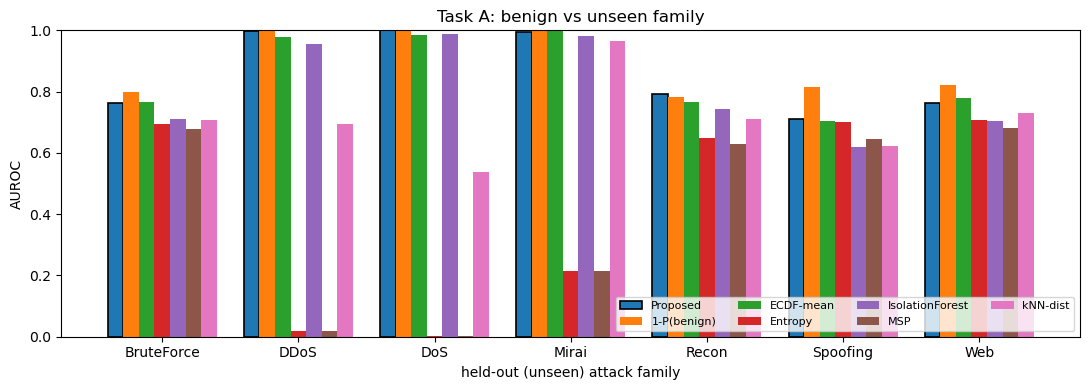

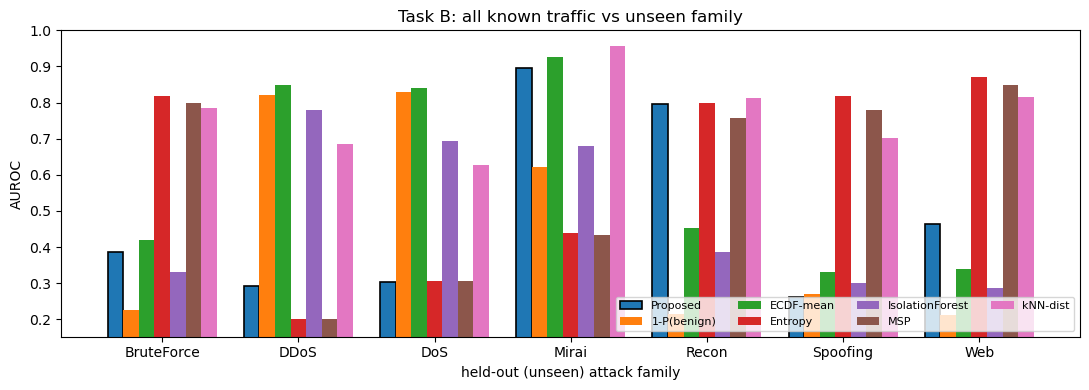

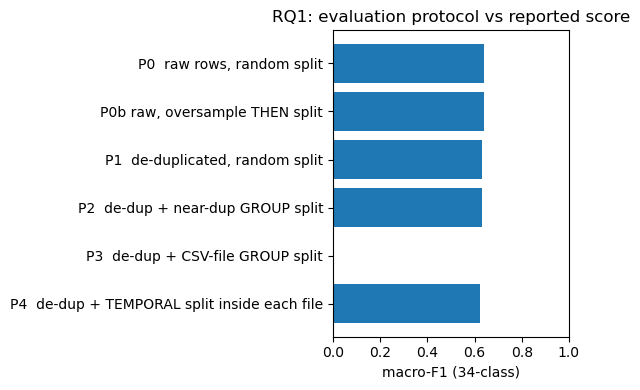

In [12]:
# ---- Figures
def bar_fig(task, fname):
    pv = lofo[lofo.task == task].pivot(index="fold", columns="method", values="auroc")
    order = ["Proposed"] + [c for c in pv.columns if c != "Proposed"]; pv = pv[order]
    fig, ax = plt.subplots(figsize=(11, 4)); w = 0.8 / len(order); x = np.arange(len(pv))
    for k, c in enumerate(order):
        ax.bar(x + k * w, pv[c], w, label=c, edgecolor="black" if c == "Proposed" else None, linewidth=1.2)
    ax.set_xticks(x + 0.4 - w / 2); ax.set_xticklabels(pv.index, rotation=0)
    ax.set_ylabel("AUROC"); ax.set_xlabel("held-out (unseen) attack family")
    ax.set_title(f"Task {task}: " + ("benign vs unseen family" if task == "A" else "all known traffic vs unseen family"))
    ax.set_ylim(max(0, np.nanmin(pv.to_numpy()) - 0.05), 1.0); ax.legend(ncol=4, fontsize=8, loc="lower right")
    fig.tight_layout(); fig.savefig(FIG_DIR / fname, dpi=300); plt.show()

bar_fig("A", "fig_lofo_auroc_taskA.png"); bar_fig("B", "fig_lofo_auroc_taskB.png")

fig, ax = plt.subplots(figsize=(6, 4))
r1 = rq1.set_index("protocol")["macro_f1"]
ax.barh(r1.index[::-1], r1.values[::-1]); ax.set_xlabel("macro-F1 (34-class)")
ax.set_xlim(max(0, r1.min() - 0.1), 1.0); ax.set_title("RQ1: evaluation protocol vs reported score")
fig.tight_layout(); fig.savefig(FIG_DIR / "fig_rq1_protocols.png", dpi=300); plt.show()

## 6 · Optional — leave-one-ATTACK-out and novelty distance

Set `RUN_LOAO = True` in the config cell. Each of the 33 attacks is withheld in turn (fine-grained labels are the classes). Baselines only (no pseudo-unseen meta-learner at this granularity — it would need ~1000 model fits). Also records which known attack the unseen one is **confused with**, and correlates a **novelty ratio** (median kNN distance of the unseen attack ÷ that of known test traffic) with detection performance.

Note the DDoS/DoS overlap: a held-out `DoS-SYN_Flood` is very similar to the known `DDoS-SYN_Flood`, so low detectability there is expected and itself a finding.

In [13]:
if not RUN_LOAO:
    print("RUN_LOAO is False -> skipped. Set RUN_LOAO = True in the config cell to run Section 6.")
else:
    wsl = ws[ws["family"] != "Other"].reset_index(drop=True)
    atk = sorted(l for l in wsl["label"].unique() if not l.lower().startswith("benign"))
    if cfg["loao_max_labels"]: atk = atk[:cfg["loao_max_labels"]]
    rows = []; t0 = time.time()
    for i, lab in enumerate(atk):
        known, unseen = wsl[wsl["label"] != lab], wsl[wsl["label"] == lab]
        part = group_partition(known["ng"], [0.7, 0.1, 0.2], SEED + 500 + i)
        K_tr, K_cal, K_te = known[part == 0], known[part == 1], known[part == 2]
        sc = OpenSetScorer(cfg, n_trees=cfg["loao_trees"], seed=SEED + i).fit(X_of(K_tr), K_tr["label"].to_numpy())
        cal, te, un = (cap_rows(d, cfg["eval_cap"], SEED) for d in (K_cal, K_te, unseen))
        S_cal, S_te, S_un = (sc.scores(X_of(d)) for d in (cal, te, un))
        b_te = (te["label"].str.lower().str.startswith("benign")).to_numpy()
        Mt, Mu = baseline_methods(S_te, S_cal), baseline_methods(S_un, S_cal)
        pred = pd.Series(sc.model.predict(X_of(un))).value_counts(normalize=True)
        row = dict(attack=lab, family=label_to_family(lab), n_unseen=len(un), confused_with=pred.index[0],
                   confused_share=round(float(pred.iloc[0]), 3),
                   same_family_confusion=label_to_family(pred.index[0]) == label_to_family(lab),
                   novelty_ratio=float(np.median(S_un["knn"]) / max(np.median(S_te["knn"]), 1e-9)))
        for m in Mt:
            row[f"auroc_A_{m}"] = eval_scores(Mt[m][b_te], Mu[m])["auroc"]
            row[f"auroc_B_{m}"] = eval_scores(Mt[m], Mu[m])["auroc"]
        rows.append(row)
        print(f"  [{i+1}/{len(atk)}] {lab:<28} ({time.time()-t0:.0f}s)")
    loao = pd.DataFrame(rows); loao.to_csv(TAB_DIR / "loao_results.csv", index=False)
    display(loao.round(3))

    if len(loao) >= 5:
        for col in ("auroc_B_kNN-dist", "auroc_B_MSP", "auroc_A_1-P(benign)"):
            rho, p = stats.spearmanr(loao["novelty_ratio"], loao[col])
            print(f"Spearman(novelty_ratio, {col}) = {rho:.3f}  (p={p:.3g})")
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.scatter(loao["novelty_ratio"], loao["auroc_B_kNN-dist"], c=loao["same_family_confusion"].map({True: "tab:red", False: "tab:blue"}))
    ax.set_xscale("log"); ax.set_xlabel("novelty ratio (median kNN dist unseen / known)"); ax.set_ylabel("AUROC (Task B, kNN-dist)")
    ax.set_title("Detectability vs novelty (red = confused with same family)")
    fig.tight_layout(); fig.savefig(FIG_DIR / "fig_loao_novelty.png", dpi=300); plt.show()

RUN_LOAO is False -> skipped. Set RUN_LOAO = True in the config cell to run Section 6.


## 7 · Save artifacts and what to check before writing

Everything is in `CICIoT2023_OpenSet_RUN\\<PROFILE>\\` (tables, figures, artifacts, logs) and `_shared\\` (inventory, audit, clean data). Before writing the paper:
- Re-run with `PROFILE = "full"` and at least 3 different `SEED` values (change `SEED`, rerun Sections 2–5), reporting mean ± std across seeds.
- Check `labels_mapped_to_Other` in the audit summary is empty; check the largest near-dup group share (a very large group makes group splits unbalanced).
- Report RQ1 (protocol drop) and the conformal check (`conf_fpr` ≈ `ALPHA` on known traffic) next to the headline detection numbers.
- RQ4 (cross-dataset) is not implemented here: it needs a second dataset with a feature-alignment step, which depends on that dataset's columns.

In [14]:
with open(ART_DIR / "lofo_artifacts.pkl", "wb") as fh:
    pickle.dump(dict(art=art, cfg=cfg, PROFILE=PROFILE, SEED=SEED, ALPHA=ALPHA, FEATS=FEATS), fh)
print("Everything is under:", RUN_ROOT)
for p in sorted(RUN_ROOT.rglob("*")):
    if p.is_file() and "02_clean_parquet" not in p.parts: print("  ", p.relative_to(RUN_ROOT))

Everything is under: C:\Users\kiani\DTESI2027_IoT_Security\CICIoT2023_OpenSet_RUN
   _shared\00_inventory\feature_profile.csv
   _shared\00_inventory\files_inventory.csv
   _shared\00_inventory\folder_summary.csv
   _shared\00_inventory\header_check.json
   _shared\00_inventory\non_csv_files.csv
   _shared\01_audit\file_manifest.csv
   _shared\01_audit\label_audit.csv
   _shared\01_audit\label_conflict_pairs.csv
   _shared\01_audit\meta.json
   _shared\01_audit\raw_sample.parquet
   _shared\01_audit\summary.json
   README_RUN.txt
   smoke\artifacts\lofo_artifacts.pkl
   smoke\figures\fig_lofo_auroc_taskA.png
   smoke\figures\fig_lofo_auroc_taskB.png
   smoke\figures\fig_rq1_protocols.png
   smoke\logs\run_log.txt
   smoke\run_config.json
   smoke\tables\ablation_raw.csv
   smoke\tables\ablation_summary.csv
   smoke\tables\conformal_check.csv
   smoke\tables\lofo_results.csv
   smoke\tables\paired_bootstrap.csv
   smoke\tables\rq1_protocols.csv
   smoke\tables\stats_wilcoxon.csv
   smok